In [103]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.neural_network import MLPClassifier
from sklearn.datasets import fetch_openml
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

In [3]:
fashion_mnist = fetch_openml(as_frame=False, name='Fashion-MNIST')


In [42]:
target = fashion_mnist.target.astype(int)

X_train, y_train = fashion_mnist.data[:60000], target[:60000]
X_test, y_test = fashion_mnist.data[60000: ], target[60000: ]

target_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
                'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']




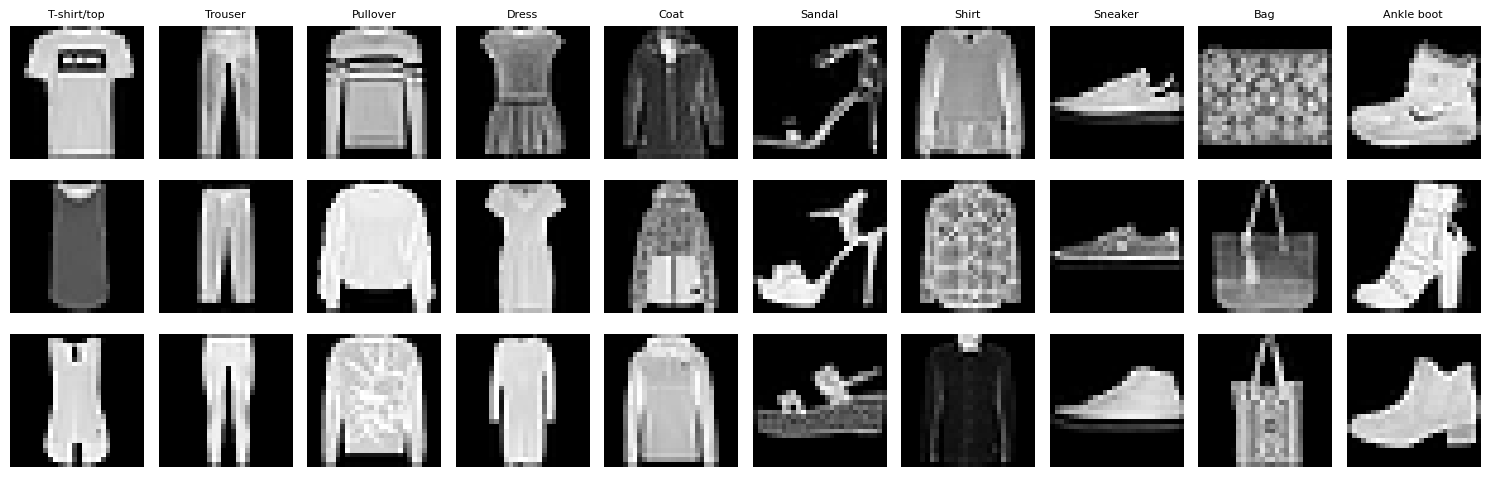

In [67]:
fig, ax = plt.subplots(3, 10, figsize=(15, 5))
for c in range(10):
    idx = np.where(y_train == c)[0][:3]
    for r in range(3):
        ax[r, c].imshow(X_train[idx[r]].reshape(28, 28), cmap='gray')
        ax[r, c].axis('off')
        if r == 0:
            ax[r, c].set_title(target_names[c], fontsize=8)
plt.tight_layout()
plt.show()

In [74]:
model = MLPClassifier(
    solver='adam',
    learning_rate_init=1e-4,
    max_iter=20000,
    early_stopping=True,
    validation_fraction=0.1,
    verbose=True,
    beta_1=0.9,
    beta_2=0.99,
    hidden_layer_sizes=(64, 32),
    tol=1e-6,
    activation='relu',
    n_iter_no_change=15
)
model = make_pipeline(MinMaxScaler(), model)
model.fit(X_train, y_train)


Iteration 1, loss = 1.38615226
Validation score: 0.739833
Iteration 2, loss = 0.71558899
Validation score: 0.807167
Iteration 3, loss = 0.58359462
Validation score: 0.824167
Iteration 4, loss = 0.52778053
Validation score: 0.835333
Iteration 5, loss = 0.49481652
Validation score: 0.838500
Iteration 6, loss = 0.47178369
Validation score: 0.849167
Iteration 7, loss = 0.45384523
Validation score: 0.850000
Iteration 8, loss = 0.44043460
Validation score: 0.854833
Iteration 9, loss = 0.42954424
Validation score: 0.859333
Iteration 10, loss = 0.42077305
Validation score: 0.860500
Iteration 11, loss = 0.41297317
Validation score: 0.861167
Iteration 12, loss = 0.40582991
Validation score: 0.864333
Iteration 13, loss = 0.39954419
Validation score: 0.861500
Iteration 14, loss = 0.39358210
Validation score: 0.863667
Iteration 15, loss = 0.38896938
Validation score: 0.867000
Iteration 16, loss = 0.38384743
Validation score: 0.867833
Iteration 17, loss = 0.37986734
Validation score: 0.870000
Iterat

Pipeline(steps=[('minmaxscaler', MinMaxScaler()),
                ('mlpclassifier',
                 MLPClassifier(beta_2=0.99, early_stopping=True,
                               hidden_layer_sizes=(64, 32),
                               learning_rate_init=0.0001, max_iter=20000,
                               n_iter_no_change=15, tol=1e-06, verbose=True))])

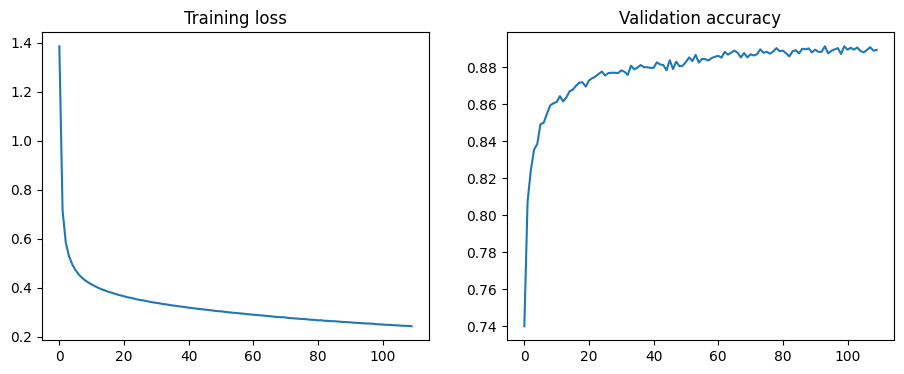

In [79]:
mlp = model[-1]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(mlp.loss_curve_); ax[0].set_title('Training loss')
ax[1].plot(mlp.validation_scores_); ax[1].set_title('Validation accuracy')
plt.show()

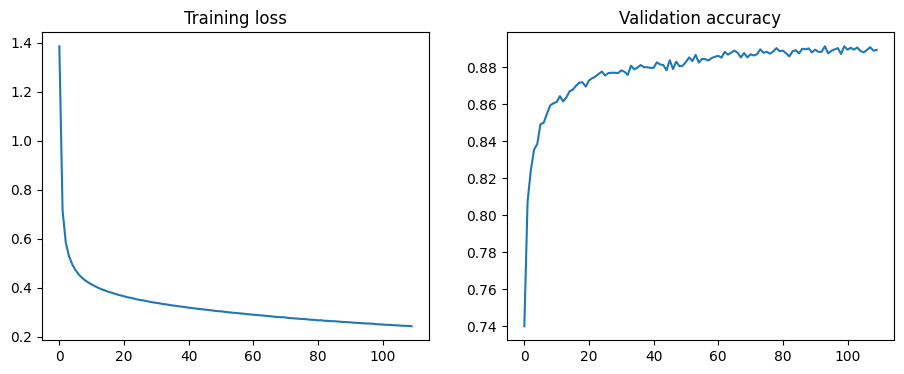

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(mlp.loss_curve_); ax[0].set_title('Training loss')
ax[1].plot(mlp.validation_scores_); ax[1].set_title('Validation accuracy')
plt.show()

In [86]:
target_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

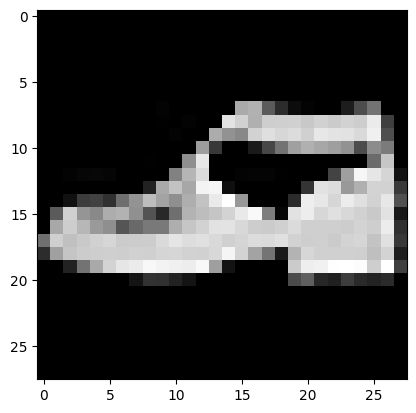

[[0.    0.    0.    0.    0.    0.678 0.    0.125 0.002 0.195]]
Model Prediction Sandal
Actual Ankle boot


In [101]:
plt.imshow(X_test[23].reshape(28, 28), cmap='gray')

plt.show()
print(np.round(model.predict_proba(X_test[23].reshape(1, -1)), 3))
print(f'Model Prediction {target_names[model.predict(X_test[23].reshape(1, -1))[0]]}')
print(f'Actual {target_names[y_test[23]]}')

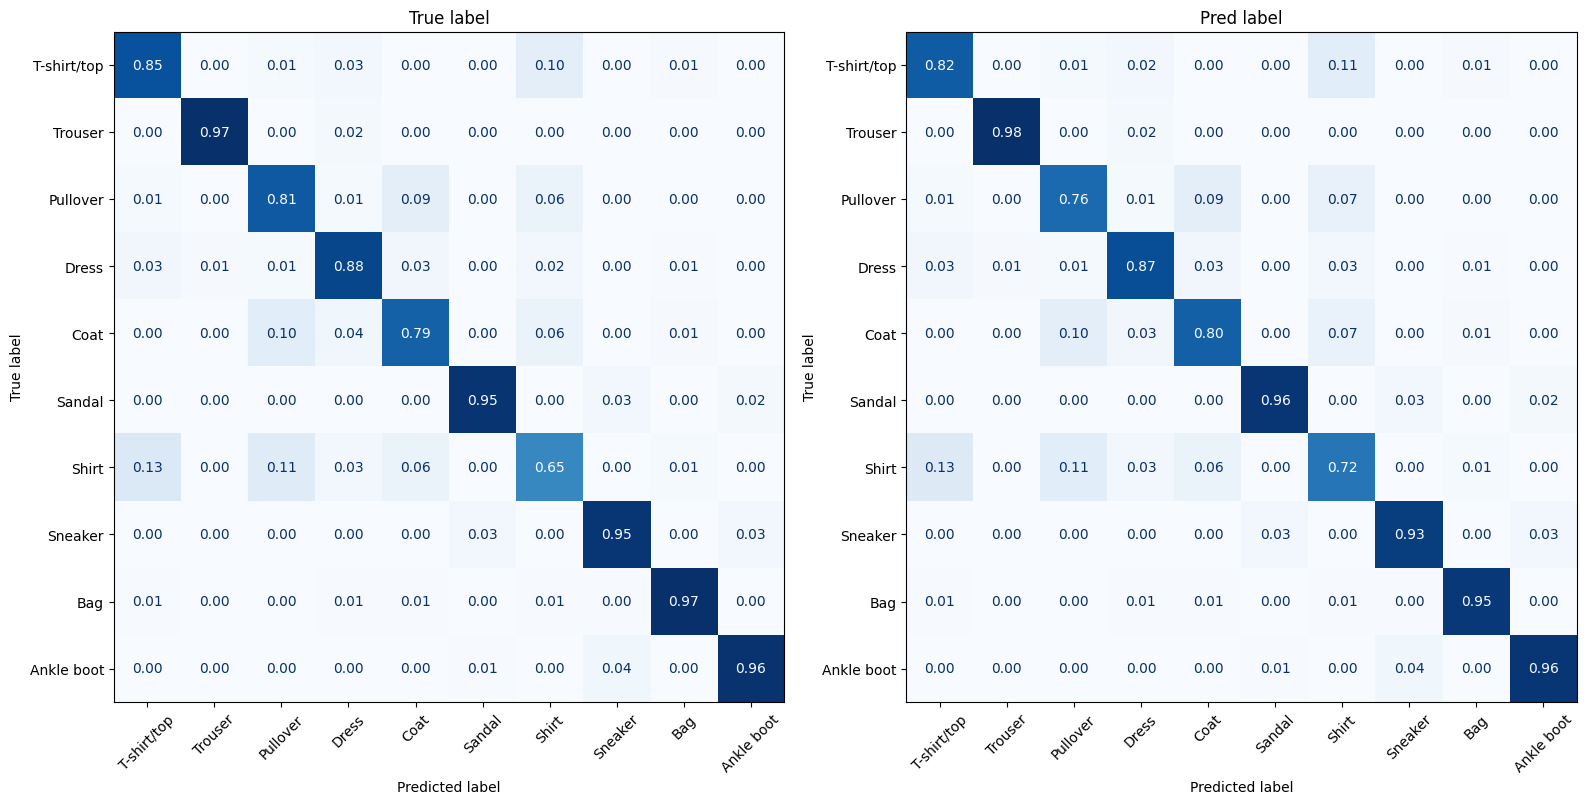

In [116]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
for i, by in enumerate(['true', 'pred']):

  display = ConfusionMatrixDisplay.from_estimator(model, X_test, y_test,
                                        display_labels=target_names, xticks_rotation=45,
                                        cmap='Blues', normalize=by, values_format='.2f', ax=ax[i], colorbar=False
                                        )

  ax[i].set_title(f'{by.capitalize()} label')
plt.tight_layout()

plt.show()

In [ ]:
confusion_matrix( no